In [ ]:
!pip install kagglehub -q
!pip install nltk wordcloud -q

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

import re
import nltk

from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from wordcloud import WordCloud

In [ ]:
import kagglehub

path = kagglehub.dataset_download(
    "danielihenacho/amazon-reviews-dataset"
)

print("Dataset path:", path)

100%|██████████| 960k/960k [00:00<00:00, 21.8MB/s]

Extracting files...


Dataset path: /root/.cache/kagglehub/datasets/danielihenacho/amazon-reviews-dataset/versions/1


In [ ]:
import os
import pandas as pd

csv_file = os.path.join(path, "cleaned_reviews.csv")

df = pd.read_csv(csv_file)

df.head()

,sentiments,cleaned_review,cleaned_review_length,review_score
0,positive,i wish would have gotten one earlier love it a...,19,5.0
1,neutral,i ve learned this lesson again open the packag...,88,1.0
2,neutral,it is so slow and lags find better option,9,2.0
3,neutral,roller ball stopped working within months of m...,12,1.0
4,neutral,i like the color and size but it few days out ...,21,1.0


In [ ]:
print("Sentiment Categories:")
print(df["sentiments"].value_counts())

Sentiment Categories:
sentiments
positive    9503
neutral     6303
negative    1534
Name: count, dtype: int64


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (17340, 4)

Columns:
['sentiments', 'cleaned_review', 'cleaned_review_length', 'review_score']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17340 entries, 0 to 17339
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   sentiments             17340 non-null  object 
 1   cleaned_review         17337 non-null  object 
 2   cleaned_review_length  17340 non-null  int64  
 3   review_score           17340 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 542.0+ KB


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
sentiments               0
cleaned_review           3
cleaned_review_length    0
review_score             0
dtype: int64


In [ ]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 1348


In [ ]:
print("Review Scores:")
print(df["review_score"].value_counts().sort_index())

Review Scores:
review_score
1.0    3898
2.0    1295
3.0    1117
4.0    1714
5.0    9316
Name: count, dtype: int64


In [ ]:
df_clean = df.dropna(subset=["cleaned_review"]).copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

Original dataset shape: (17340, 4)
Cleaned dataset shape: (17337, 4)


In [ ]:
print("Duplicate rows before removal:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print("Dataset shape after cleaning:", df_clean.shape)

Duplicate rows before removal: 1347
Dataset shape after cleaning: (15990, 4)


In [ ]:
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

print("\nMissing values in original dataset:")
print(df.isnull().sum())

print("\nDuplicate rows in original dataset:")
print(df.duplicated().sum())

Original shape: (17340, 4)
Cleaned shape: (15990, 4)

Missing values in original dataset:
sentiments               0
cleaned_review           3
cleaned_review_length    0
review_score             0
dtype: int64

Duplicate rows in original dataset:
1348


In [ ]:
print("Rows with missing review:")
print(df[df["cleaned_review"].isnull()])

Rows with missing review:
     sentiments cleaned_review  cleaned_review_length  review_score
2085    neutral            NaN                      0           5.0
6043    neutral            NaN                      0           5.0
9526    neutral            NaN                      0           4.0


In [ ]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remove rows with missing review text
df_clean = df_clean.dropna(subset=["cleaned_review"])

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

print("Original dataset shape:", df.shape)
print("Final cleaned dataset shape:", df_clean.shape)

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nDuplicate rows after cleaning:")
print(df_clean.duplicated().sum())

Original dataset shape: (17340, 4)
Final cleaned dataset shape: (15990, 4)

Missing values after cleaning:
sentiments               0
cleaned_review           0
cleaned_review_length    0
review_score             0
dtype: int64

Duplicate rows after cleaning:
0


In [ ]:
print(df_clean["sentiments"].value_counts())
print(df_clean["sentiments"].value_counts(normalize=True) * 100)
print(df_clean["review_score"].value_counts().sort_index())

sentiments
positive    8800
neutral     5760
negative    1430
Name: count, dtype: int64
sentiments
positive    55.034396
neutral     36.022514
negative     8.943089
Name: proportion, dtype: float64
review_score
1.0    3544
2.0    1261
3.0    1097
4.0    1669
5.0    8419
Name: count, dtype: int64


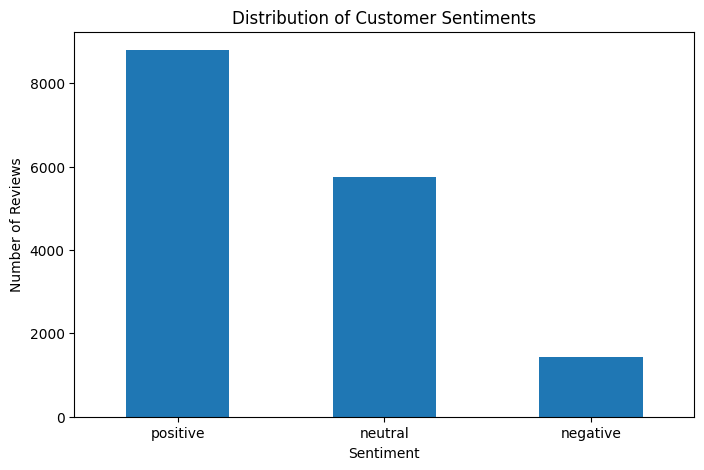

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

df_clean["sentiments"].value_counts().plot(
    kind="bar"
)

plt.title("Distribution of Customer Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.xticks(rotation=0)

plt.show()

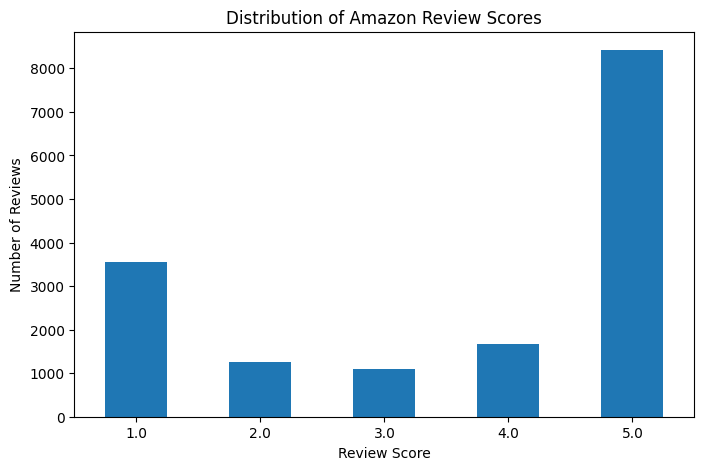

In [ ]:
plt.figure(figsize=(8, 5))

df_clean["review_score"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Distribution of Amazon Review Scores")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")

plt.xticks(rotation=0)

plt.show()

In [ ]:
# Review length statistical summary
review_length_stats = df_clean["cleaned_review_length"].describe()

print(review_length_stats)

count    15990.000000
mean        31.048155
std         36.081638
min          0.000000
25%          9.000000
50%         20.000000
75%         39.000000
max        571.000000
Name: cleaned_review_length, dtype: float64


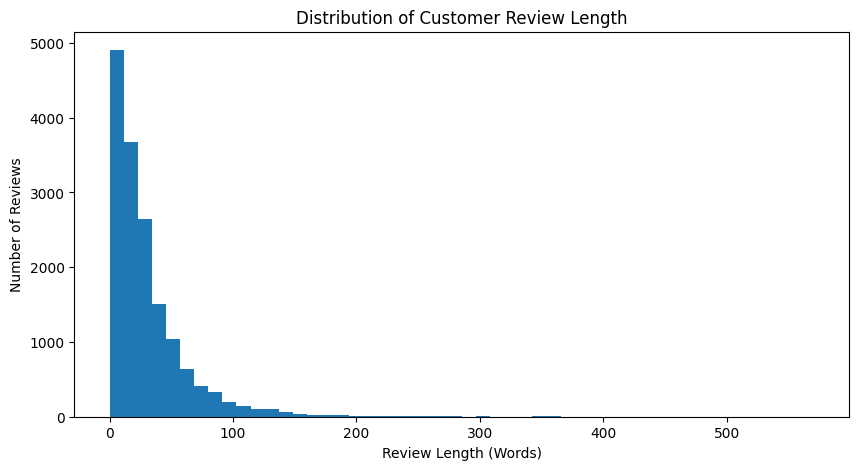

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(df_clean["cleaned_review_length"], bins=50)

plt.title("Distribution of Customer Review Length")
plt.xlabel("Review Length (Words)")
plt.ylabel("Number of Reviews")

plt.show()

In [ ]:
avg_review_length = (
    df_clean.groupby("sentiments")["cleaned_review_length"]
    .mean()
    .sort_values()
)

print(avg_review_length)

sentiments
neutral     23.352604
positive    33.955341
negative    44.155245
Name: cleaned_review_length, dtype: float64


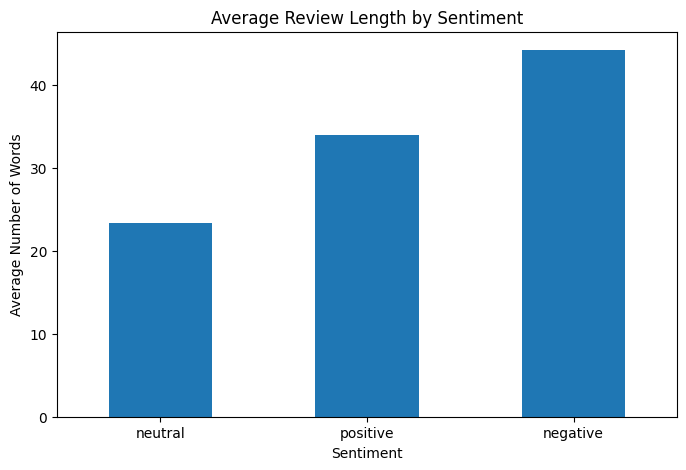

In [ ]:
plt.figure(figsize=(8, 5))

avg_review_length.plot(kind="bar")

plt.title("Average Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Number of Words")

plt.xticks(rotation=0)

plt.show()

In [ ]:
sentiment_score = pd.crosstab(
    df_clean["sentiments"],
    df_clean["review_score"]
)

print(sentiment_score)

review_score   1.0  2.0  3.0  4.0   5.0
sentiments                             
negative       406  126  101  140   657
neutral       1469  505  433  584  2769
positive      1669  630  563  945  4993


In [ ]:
sentiment_score_percentage = pd.crosstab(
    df_clean["sentiments"],
    df_clean["review_score"],
    normalize="index"
) * 100

print(sentiment_score_percentage.round(2))

review_score    1.0   2.0   3.0    4.0    5.0
sentiments                                   
negative      28.39  8.81  7.06   9.79  45.94
neutral       25.50  8.77  7.52  10.14  48.07
positive      18.97  7.16  6.40  10.74  56.74


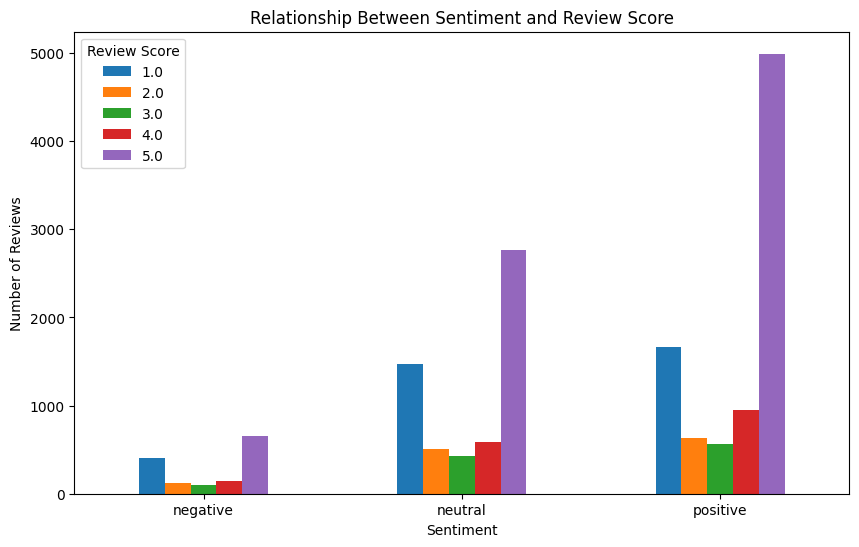

In [ ]:
sentiment_score.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Relationship Between Sentiment and Review Score")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.legend(title="Review Score")

plt.xticks(rotation=0)

plt.show()

In [ ]:
print("Reviews with zero length:")
print((df_clean["cleaned_review_length"] == 0).sum())

Reviews with zero length:
3


In [ ]:
# Count zero-length reviews
zero_length_count = (df_clean["cleaned_review_length"] == 0).sum()

print("Number of zero-length reviews:", zero_length_count)

# Display a few examples
df_clean[df_clean["cleaned_review_length"] == 0].head()

Number of zero-length reviews: 3


,sentiments,cleaned_review,cleaned_review_length,review_score
2894,neutral,,0,5.0
6841,neutral,,0,4.0
10063,neutral,,0,3.0


In [ ]:
# Remove zero-length reviews
df_clean = df_clean[df_clean["cleaned_review_length"] > 0].copy()

print("Final dataset shape:", df_clean.shape)

print("Zero-length reviews remaining:",
      (df_clean["cleaned_review_length"] == 0).sum())

Final dataset shape: (15987, 4)
Zero-length reviews remaining: 0


In [ ]:
# Statistical Analysis

numerical_columns = [
    "cleaned_review_length",
    "review_score"
]

statistical_results = pd.DataFrame({
    "Mean": df_clean[numerical_columns].mean(),
    "Median": df_clean[numerical_columns].median(),
    "Mode": df_clean[numerical_columns].mode().iloc[0],
    "Variance": df_clean[numerical_columns].var(),
    "Standard Deviation": df_clean[numerical_columns].std(),
    "Skewness": df_clean[numerical_columns].skew()
})

print("Statistical Analysis Results:")
display(statistical_results)

Statistical Analysis Results:


,Mean,Median,Mode,Variance,Standard Deviation,Skewness
cleaned_review_length,31.053981,20.0,5.0,1301.947980,36.082516,4.101440
review_score,3.635204,5.0,5.0,2.772833,1.665183,-0.666203


In [ ]:
# Review Length Statistics
print("REVIEW LENGTH STATISTICS")
print("Mean:", df_clean["cleaned_review_length"].mean())
print("Median:", df_clean["cleaned_review_length"].median())
print("Mode:", df_clean["cleaned_review_length"].mode().tolist())
print("Variance:", df_clean["cleaned_review_length"].var())
print("Standard Deviation:", df_clean["cleaned_review_length"].std())
print("Skewness:", df_clean["cleaned_review_length"].skew())

REVIEW LENGTH STATISTICS
Mean: 31.05398135985488
Median: 20.0
Mode: [5]
Variance: 1301.9479803632282
Standard Deviation: 36.082516269839445
Skewness: 4.1014403125868695


In [ ]:
# Review Score Statistics
print("REVIEW SCORE STATISTICS")
print("Mean:", df_clean["review_score"].mean())
print("Median:", df_clean["review_score"].median())
print("Mode:", df_clean["review_score"].mode().tolist())
print("Variance:", df_clean["review_score"].var())
print("Standard Deviation:", df_clean["review_score"].std())
print("Skewness:", df_clean["review_score"].skew())

REVIEW SCORE STATISTICS
Mean: 3.6352036029273784
Median: 5.0
Mode: [5.0]
Variance: 2.7728329420907087
Standard Deviation: 1.6651825551844786
Skewness: -0.6662030757539743


In [ ]:
positive_probability = (
    df_clean["sentiments"] == "positive"
).mean()

print("Probability of Positive Review:", positive_probability)

Probability of Positive Review: 0.5504472383811847


In [ ]:
# Random sample of 500 reviews
sample_df = df_clean.sample(
    n=500,
    random_state=42
)

print("Sample Shape:", sample_df.shape)

sample_df.head()

Sample Shape: (500, 4)


,sentiments,cleaned_review,cleaned_review_length,review_score
17328,positive,got to say that am fan of these speakers bough...,50,5.0
8773,positive,grandson loved it for gaming,5,4.0
150,neutral,it no for me,4,3.0
1696,positive,multi use can use this mouse for anything you ...,19,2.0
8455,neutral,can even press most three key combinations try...,31,5.0


In [ ]:
from scipy import stats

# Perform one-sample t-test
t_statistic, p_value_two_tailed = stats.ttest_1samp(
    df_clean["review_score"],
    popmean=3
)

# Convert two-tailed p-value to one-tailed p-value
if t_statistic > 0:
    p_value = p_value_two_tailed / 2
else:
    p_value = 1 - (p_value_two_tailed / 2)

print("T-statistic:", t_statistic)
print("Two-tailed p-value:", p_value_two_tailed)
print("One-tailed p-value:", p_value)

alpha = 0.05

if p_value < alpha and t_statistic > 0:
    print("\nReject the Null Hypothesis")
    print("Conclusion: The average review score is significantly greater than 3.")
else:
    print("\nFail to Reject the Null Hypothesis")
    print("Conclusion: There is insufficient evidence that the average review score is greater than 3.")

T-statistic: 48.231924139289184
Two-tailed p-value: 0.0
One-tailed p-value: 0.0

Reject the Null Hypothesis
Conclusion: The average review score is significantly greater than 3.


In [ ]:
import nltk

# Download required NLTK resources
nltk.download("punkt")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [ ]:
import nltk
import re

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download required NLTK resources
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [ ]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove special characters and numbers
    text = re.sub(r"[^a-zA-Z\s]", "", text)

    # Tokenization
    words = word_tokenize(text)

    # Remove stopwords and apply lemmatization
    processed_words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    # Convert back to text
    return " ".join(processed_words)

In [ ]:
# Apply NLP preprocessing to all reviews
df_clean["processed_review"] = (
    df_clean["cleaned_review"]
    .apply(preprocess_text)
)

print("NLP preprocessing completed!")
print("Dataset shape:", df_clean.shape)

df_clean[
    ["cleaned_review", "processed_review", "sentiments"]
].head()

NLP preprocessing completed!
Dataset shape: (15987, 5)


,cleaned_review,processed_review,sentiments
0,i wish would have gotten one earlier love it a...,wish would gotten one earlier love make workin...,positive
1,i ve learned this lesson again open the packag...,learned lesson open package use product right ...,neutral
2,it is so slow and lags find better option,slow lag find better option,neutral
3,roller ball stopped working within months of m...,roller ball stopped working within month minim...,neutral
4,i like the color and size but it few days out ...,like color size day return period hold charge,neutral


In [ ]:
empty_processed = (
    df_clean["processed_review"].str.strip() == ""
).sum()

print("Empty processed reviews:", empty_processed)

Empty processed reviews: 8


In [ ]:
# Remove reviews that became empty after preprocessing
df_clean = df_clean[
    df_clean["processed_review"].str.strip() != ""
].copy()

print("Final dataset shape:", df_clean.shape)

# Verify
empty_processed = (
    df_clean["processed_review"].str.strip() == ""
).sum()

print("Empty processed reviews remaining:", empty_processed)

Final dataset shape: (15979, 5)
Empty processed reviews remaining: 0


In [ ]:
# Input feature (processed review text)
X = df_clean["processed_review"]

# Target variable (sentiment)
y = df_clean["sentiments"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nSentiment Distribution:")
print(y.value_counts())

Feature shape: (15979,)
Target shape: (15979,)

Sentiment Distribution:
sentiments
positive    8800
neutral     5749
negative    1430
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (12783,)
Testing data: (3196,)


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

bow_vectorizer = CountVectorizer(
    max_features=5000
)

X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

print("Training Bag of Words shape:", X_train_bow.shape)
print("Testing Bag of Words shape:", X_test_bow.shape)

Training Bag of Words shape: (12783, 5000)
Testing Bag of Words shape: (3196, 5000)


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (12783, 5000)
Testing TF-IDF shape: (3196, 5000)


In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

# Create model
nb_bow = MultinomialNB()

# Train model
nb_bow.fit(X_train_bow, y_train)

# Make predictions
y_pred_nb_bow = nb_bow.predict(X_test_bow)

# Accuracy
accuracy_nb_bow = accuracy_score(y_test, y_pred_nb_bow)

print("Naive Bayes + Bag of Words Accuracy:")
print(round(accuracy_nb_bow * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb_bow))

Naive Bayes + Bag of Words Accuracy:
72.09 %

Classification Report:
              precision    recall  f1-score   support

    negative       0.61      0.36      0.45       286
     neutral       0.67      0.55      0.61      1150
    positive       0.75      0.89      0.82      1760

    accuracy                           0.72      3196
   macro avg       0.68      0.60      0.62      3196
weighted avg       0.71      0.72      0.71      3196



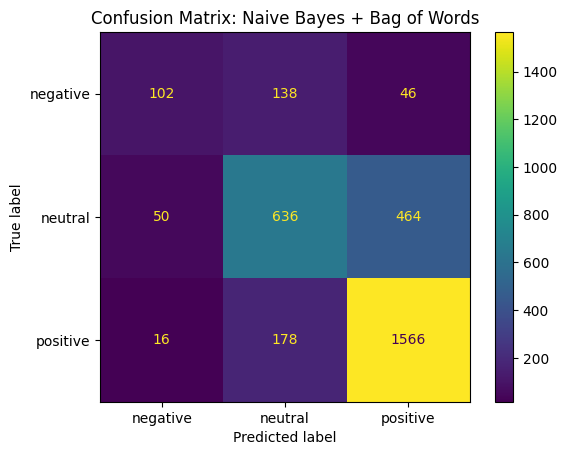

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_nb_bow = confusion_matrix(
    y_test,
    y_pred_nb_bow
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb_bow,
    display_labels=nb_bow.classes_
)

disp.plot()

plt.title("Confusion Matrix: Naive Bayes + Bag of Words")
plt.show()

In [ ]:
# Create Naive Bayes model
nb_tfidf = MultinomialNB()

# Train the model
nb_tfidf.fit(X_train_tfidf, y_train)

# Make predictions
y_pred_nb_tfidf = nb_tfidf.predict(X_test_tfidf)

# Calculate accuracy
accuracy_nb_tfidf = accuracy_score(
    y_test,
    y_pred_nb_tfidf
)

print("Naive Bayes + TF-IDF Accuracy:")
print(round(accuracy_nb_tfidf * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb_tfidf))

Naive Bayes + TF-IDF Accuracy:
69.37 %

Classification Report:
              precision    recall  f1-score   support

    negative       1.00      0.01      0.02       286
     neutral       0.63      0.52      0.57      1150
    positive       0.72      0.92      0.81      1760

    accuracy                           0.69      3196
   macro avg       0.78      0.48      0.47      3196
weighted avg       0.71      0.69      0.65      3196



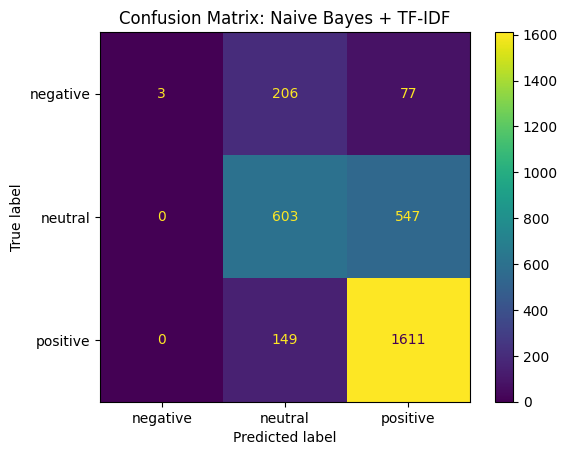

In [ ]:
cm_nb_tfidf = confusion_matrix(
    y_test,
    y_pred_nb_tfidf
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb_tfidf,
    display_labels=nb_tfidf.classes_
)

disp.plot()

plt.title("Confusion Matrix: Naive Bayes + TF-IDF")

plt.show()

In [ ]:
print(round(accuracy_nb_tfidf * 100, 2), "%")
print(classification_report(y_test, y_pred_nb_tfidf))

69.37 %
              precision    recall  f1-score   support

    negative       1.00      0.01      0.02       286
     neutral       0.63      0.52      0.57      1150
    positive       0.72      0.92      0.81      1760

    accuracy                           0.69      3196
   macro avg       0.78      0.48      0.47      3196
weighted avg       0.71      0.69      0.65      3196



In [ ]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
lr_bow = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
lr_bow.fit(X_train_bow, y_train)

# Predictions
y_pred_lr_bow = lr_bow.predict(X_test_bow)

# Accuracy
accuracy_lr_bow = accuracy_score(
    y_test,
    y_pred_lr_bow
)

print("Logistic Regression + Bag of Words Accuracy:")
print(round(accuracy_lr_bow * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr_bow))

Logistic Regression + Bag of Words Accuracy:
84.7 %

Classification Report:
              precision    recall  f1-score   support

    negative       0.67      0.52      0.59       286
     neutral       0.78      0.83      0.81      1150
    positive       0.91      0.91      0.91      1760

    accuracy                           0.85      3196
   macro avg       0.79      0.76      0.77      3196
weighted avg       0.85      0.85      0.85      3196



In [ ]:
# Create Logistic Regression model
lr_tfidf = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
lr_tfidf.fit(X_train_tfidf, y_train)

# Make predictions
y_pred_lr_tfidf = lr_tfidf.predict(X_test_tfidf)

# Calculate accuracy
accuracy_lr_tfidf = accuracy_score(
    y_test,
    y_pred_lr_tfidf
)

print("Logistic Regression + TF-IDF Accuracy:")
print(round(accuracy_lr_tfidf * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr_tfidf))

Logistic Regression + TF-IDF Accuracy:
82.45 %

Classification Report:
              precision    recall  f1-score   support

    negative       0.74      0.35      0.48       286
     neutral       0.75      0.82      0.78      1150
    positive       0.89      0.90      0.89      1760

    accuracy                           0.82      3196
   macro avg       0.79      0.69      0.72      3196
weighted avg       0.82      0.82      0.82      3196



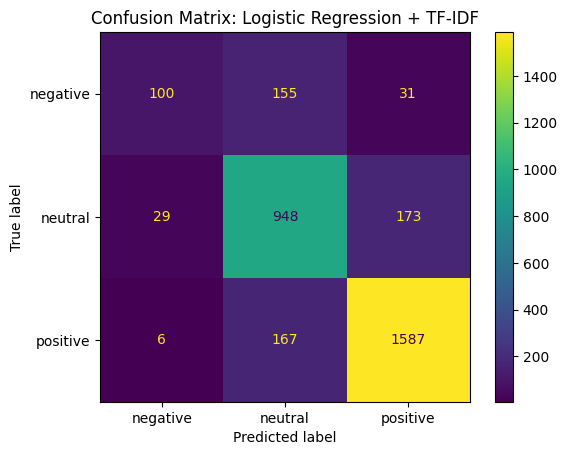

In [ ]:
cm_lr_tfidf = confusion_matrix(
    y_test,
    y_pred_lr_tfidf
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr_tfidf,
    display_labels=lr_tfidf.classes_
)

disp.plot()

plt.title("Confusion Matrix: Logistic Regression + TF-IDF")

plt.show()

In [ ]:
model_results = pd.DataFrame({
    "Model": [
        "Naive Bayes",
        "Naive Bayes",
        "Logistic Regression",
        "Logistic Regression"
    ],
    "Feature Extraction": [
        "Bag of Words",
        "TF-IDF",
        "Bag of Words",
        "TF-IDF"
    ],
    "Accuracy (%)": [
        accuracy_nb_bow * 100,
        accuracy_nb_tfidf * 100,
        accuracy_lr_bow * 100,
        accuracy_lr_tfidf * 100
    ]
})

model_results = model_results.sort_values(
    by="Accuracy (%)",
    ascending=False
)

display(model_results)

,Model,Feature Extraction,Accuracy (%)
2,Logistic Regression,Bag of Words,84.699625
3,Logistic Regression,TF-IDF,82.446809
0,Naive Bayes,Bag of Words,72.090113
1,Naive Bayes,TF-IDF,69.367960


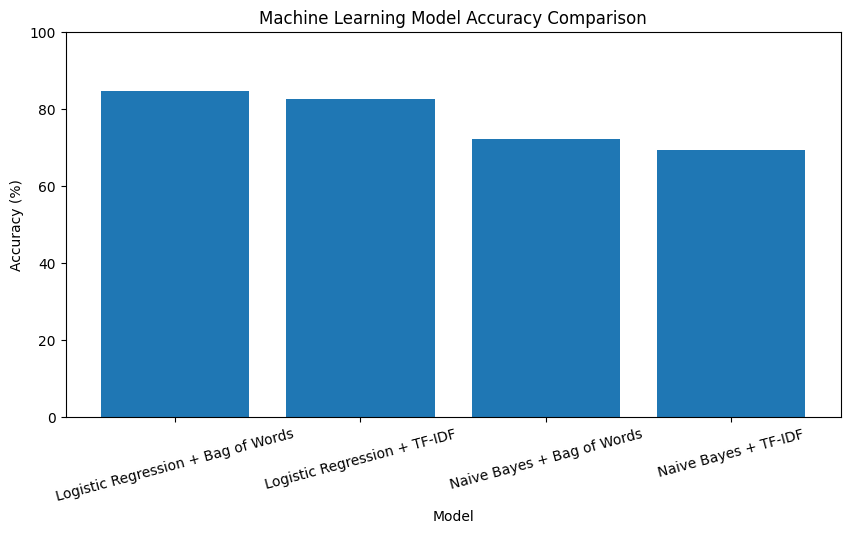

In [ ]:
plt.figure(figsize=(10, 5))

labels = (
    model_results["Model"]
    + " + "
    + model_results["Feature Extraction"]
)

plt.bar(
    labels,
    model_results["Accuracy (%)"]
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")

plt.xticks(rotation=15)

plt.ylim(0, 100)

plt.show()

In [ ]:
def predict_sentiment(review):

    # Step 1: Preprocess the review
    processed_review = preprocess_text(review)

    # Check if review becomes empty after preprocessing
    if not processed_review.strip():
        return "Unable to predict: No meaningful text found."

    # Step 2: Convert review to Bag of Words features
    review_vector = bow_vectorizer.transform([processed_review])

    # Step 3: Predict sentiment
    prediction = lr_bow.predict(review_vector)[0]

    return prediction

In [ ]:
reviews = [
    "This product is amazing and the quality is excellent",
    "The product is okay but nothing special",
    "This is the worst product I have ever purchased"
]

for review in reviews:
    print("Review:", review)
    print("Predicted Sentiment:", predict_sentiment(review))
    print("-" * 60)

Review: This product is amazing and the quality is excellent
Predicted Sentiment: positive
------------------------------------------------------------
Review: The product is okay but nothing special
Predicted Sentiment: neutral
------------------------------------------------------------
Review: This is the worst product I have ever purchased
Predicted Sentiment: neutral
------------------------------------------------------------


In [ ]:
def predict_sentiment_with_confidence(review):

    # Preprocess
    processed_review = preprocess_text(review)

    if not processed_review.strip():
        return None, "Unable to predict: No meaningful text found."

    # Convert to Bag of Words
    review_vector = bow_vectorizer.transform([processed_review])

    # Predict sentiment
    prediction = lr_bow.predict(review_vector)[0]

    # Get prediction probabilities
    probabilities = lr_bow.predict_proba(review_vector)[0]

    # Get confidence
    confidence = max(probabilities) * 100

    return prediction, confidence

In [ ]:
test_reviews = [
    "This product is excellent and I love the quality",
    "This product stopped working after one day and I am disappointed",
    "The product arrived as expected and works normally"
]

for review in test_reviews:
    prediction, confidence = predict_sentiment_with_confidence(review)

    print("Review:", review)
    print("Prediction:", prediction)
    print("Confidence:", round(confidence, 2), "%")
    print("-" * 70)

Review: This product is excellent and I love the quality
Prediction: positive
Confidence: 99.82 %
----------------------------------------------------------------------
Review: This product stopped working after one day and I am disappointed
Prediction: negative
Confidence: 57.76 %
----------------------------------------------------------------------
Review: The product arrived as expected and works normally
Prediction: neutral
Confidence: 91.56 %
----------------------------------------------------------------------


In [ ]:
stop_words = set(stopwords.words("english"))

# Keep important negation words
stop_words = stop_words - {"no", "not", "nor", "never"}

In [ ]:
user_review = input("Enter an Amazon customer review: ")

sentiment = predict_sentiment(user_review)

if sentiment == "positive":
    emotion = "Happy"
elif sentiment == "negative":
    emotion = "Angry/Sad"
else:
    emotion = "Neutral"

print("\nPredicted Sentiment:", sentiment)
print("Detected Emotion:", emotion)


Enter an Amazon customer review: Very poor quality. It stopped working after just two days.”

Predicted Sentiment: negative
Detected Emotion: Angry/Sad


In [ ]:

import re
from collections import Counter

def detect_fake_review(review):
    reasons = []
    score = 0

    text = review.strip()
    words = re.findall(r"\b[a-zA-Z]+\b", text)
    lower_text = text.lower()

    # Check for very short reviews
    if len(text) < 10:
        score += 1
        reasons.append("Very short review")

    # Check for repeated words
    if len(words) >= 6:
        word_counts = Counter(word.lower() for word in words)
        repeated_words = sum(
            count > 1 for count in word_counts.values()
        )

        if repeated_words >= 3:
            score += 1
            reasons.append("Many repeated words")

    # Check excessive punctuation
    if len(re.findall(r"[!?]", text)) >= 4:
        score += 1
        reasons.append("Excessive punctuation")

    # Check promotional phrases
    promotional_phrases = [
        "best product ever",
        "must buy",
        "buy now",
        "perfect product",
        "five stars",
        "100% recommended"
    ]

    if any(phrase in lower_text for phrase in promotional_phrases):
        score += 1
        reasons.append("Promotional phrase detected")

    if score >= 2:
        result = "Potentially Suspicious"
    else:
        result = "No Strong Suspicious Signals"

    return result, reasons

print("Fake review detection function is ready.")


Fake review detection function is ready.


In [ ]:

user_review = input("Enter an Amazon customer review: ")

# Sentiment prediction
prediction = predict_sentiment(user_review)

# Simple emotion interpretation
if prediction == "positive":
    emotion = "Happy"
elif prediction == "negative":
    emotion = "Angry/Sad"
else:
    emotion = "Neutral"

# Rule-based fake review screening
fake_result, reasons = detect_fake_review(user_review)

# Display final results
print("\n===== FINAL RESULT =====")
print("Customer Review:", user_review)
print("Predicted Sentiment:", prediction)
print("Detected Emotion:", emotion)
print("Fake Review Screening:", fake_result)

if reasons:
    print("Suspicious Signals:")
    for reason in reasons:
        print("-", reason)
else:
    print("Suspicious Signals: No strong rule-based signals found")


Enter an Amazon customer review: Very poor quality. It stopped working after just two days.”

===== FINAL RESULT =====
Customer Review: Very poor quality. It stopped working after just two days.”
Predicted Sentiment: negative
Detected Emotion: Angry/Sad
Fake Review Screening: No Strong Suspicious Signals
Suspicious Signals: No strong rule-based signals found
